# Sales Data Analysis Using Python

## 1. Project Overview

This project explores retail order data to understand sales performance across time, products, customers, and regions. The analysis uses **Python, Pandas, NumPy, Matplotlib, and Seaborn**.

### Objectives
- Inspect and prepare the sales dataset.
- Measure overall and time-based sales performance.
- Identify high-performing product categories, sub-categories, and products.
- Explore customer and regional sales patterns.
- Examine the distribution of order sales and investigate unusually large transactions.
- Summarize evidence-based business insights.

> **Scope note:** The supplied dataset contains sales but does not contain profit, quantity, discount, or cost fields. Therefore, this project analyzes sales revenue only and does not make claims about profitability or units sold.

## 2. Import Libraries and Load Data

The code searches common project locations so the notebook can be run from the project root or from a `notebooks` folder.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

possible_paths = [
    Path("../data/sales.csv"),
    Path("data/sales.csv"),
    Path("sales.csv"),
]

data_path = next((path for path in possible_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "sales.csv was not found. Place it in the project data folder, "
        "or update possible_paths with its location."
    )

df_raw = pd.read_csv(data_path)
df = df_raw.copy()

print(f"Loaded file: {data_path.resolve()}")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded file: C:\Users\shabbar\OneDrive\Desktop\Sales-Data-Analysis-Project\data\sales.csv
Dataset shape: 9,800 rows × 18 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


## 3. Understand the Dataset

Review the structure, column types, descriptive statistics, and distinct values before making changes.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,"9,800.00",NaN,NaN,NaN,"4,900.50","2,829.16",1.00,"2,450.75","4,900.50","7,350.25","9,800.00"
Order ID,9800,4922,CA-2018-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9800,1230,05/09/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9800,1326,26/09/2018,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9800,4,Standard Class,5859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9800,793,WB-21850,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9800,793,William Brown,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9800,3,Consumer,5101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9800,1,United States,9800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9800,529,New York City,891,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\\nUnique values in selected categorical columns:")
for column in ["Ship Mode", "Segment", "Region", "Category", "Sub-Category"]:
    if column in df.columns:
        print(f"{column}: {df[column].nunique()}")

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']
\nUnique values in selected categorical columns:
Ship Mode: 4
Segment: 3
Region: 4
Category: 3
Sub-Category: 17


## 4. Data Quality Checks and Cleaning

Check missing values, duplicate records, date parsing, and invalid sales values. The 11 missing postal codes are not needed for the sales analysis, so they are retained rather than deleting otherwise valid transactions.

In [7]:
missing_summary = (
    df.isna().sum()
      .rename("Missing Values")
      .to_frame()
      .assign(Missing_Percent=lambda x: x["Missing Values"] / len(df) * 100)
      .sort_values("Missing Values", ascending=False)
)
display(missing_summary)

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Missing postal codes: {df['Postal Code'].isna().sum():,}")

,Missing Values,Missing_Percent
Postal Code,11,0.11
Row ID,0,0.00
Order ID,0,0.00
Order Date,0,0.00
Ship Mode,0,0.00
Ship Date,0,0.00
Customer Name,0,0.00
Segment,0,0.00
Country,0,0.00
Customer ID,0,0.00


Exact duplicate rows: 0
Missing postal codes: 11


In [8]:
# Parse dates using dayfirst=True because the supplied dates use DD/MM/YYYY.
for column in ["Order Date", "Ship Date"]:
    df[column] = pd.to_datetime(df[column], dayfirst=True, errors="coerce")

print("Unparsed Order Date values:", df["Order Date"].isna().sum())
print("Unparsed Ship Date values:", df["Ship Date"].isna().sum())
print("Missing Sales values:", df["Sales"].isna().sum())
print("Non-positive Sales values:", (df["Sales"] <= 0).sum())

# Remove exact duplicate records, if any.
df = df.drop_duplicates().copy()

# Drop rows only when fields essential to this analysis are missing.
df = df.dropna(subset=["Order Date", "Ship Date", "Sales"]).copy()

# Keep transactions with positive sales and valid shipping intervals.
df = df[df["Sales"] > 0].copy()
df = df[df["Ship Date"] >= df["Order Date"]].copy()

print(f"Rows after essential cleaning: {len(df):,}")
print(f"Remaining missing values by column:\n{df.isna().sum()}")

Unparsed Order Date values: 0
Unparsed Ship Date values: 0
Missing Sales values: 0
Non-positive Sales values: 0
Rows after essential cleaning: 9,800
Remaining missing values by column:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


### Create analysis features

Extract calendar features and calculate the number of days between order and shipment.

In [9]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["Quarter"] = df["Order Date"].dt.to_period("Q").astype(str)
df["Order Month"] = df["Order Date"].dt.to_period("M")
df["Day of Week"] = df["Order Date"].dt.day_name()
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

display(df[["Order Date", "Ship Date", "Year", "Month Name", "Quarter",
            "Day of Week", "Shipping Days", "Sales"]].head())

,Order Date,Ship Date,Year,Month Name,Quarter,Day of Week,Shipping Days,Sales
0,2017-11-08,2017-11-11,2017,Nov,2017Q4,Wednesday,3,261.96
1,2017-11-08,2017-11-11,2017,Nov,2017Q4,Wednesday,3,731.94
2,2017-06-12,2017-06-16,2017,Jun,2017Q2,Monday,4,14.62
3,2016-10-11,2016-10-18,2016,Oct,2016Q4,Tuesday,7,957.58
4,2016-10-11,2016-10-18,2016,Oct,2016Q4,Tuesday,7,22.37


## 5. Overall Sales Performance

Calculate the key measures that describe the dataset. Here, total sales is the sum of the `Sales` column; average order-line sales is the mean of that column.

In [10]:
total_sales = df["Sales"].sum()
average_line_sales = df["Sales"].mean()
median_line_sales = df["Sales"].median()
number_of_rows = len(df)
number_of_orders = df["Order ID"].nunique()
number_of_customers = df["Customer ID"].nunique()
number_of_products = df["Product ID"].nunique()

summary = pd.Series({
    "Total Sales": total_sales,
    "Average Sales per Row": average_line_sales,
    "Median Sales per Row": median_line_sales,
    "Transaction Rows": number_of_rows,
    "Unique Orders": number_of_orders,
    "Unique Customers": number_of_customers,
    "Unique Products": number_of_products,
})
display(summary.to_frame("Value"))

,Value
Total Sales,"2,261,536.78"
Average Sales per Row,230.77
Median Sales per Row,54.49
Transaction Rows,"9,800.00"
Unique Orders,"4,922.00"
Unique Customers,793.00
Unique Products,"1,861.00"


## 6. Time-Based Sales Analysis

Analyze annual, quarterly, and monthly sales. Monthly totals are ordered chronologically, not alphabetically.

In [11]:
yearly_sales = df.groupby("Year")["Sales"].sum().sort_index()
quarterly_sales = df.groupby("Quarter")["Sales"].sum().sort_index()
monthly_sales = df.groupby("Order Month")["Sales"].sum().sort_index()

display(yearly_sales.rename("Sales").to_frame())
display(quarterly_sales.rename("Sales").to_frame())
display(monthly_sales.rename("Sales").to_frame().tail(12))

,Sales
Year,
2015,"479,856.21"
2016,"459,436.01"
2017,"600,192.55"
2018,"722,052.02"


,Sales
Quarter,
2015Q1,"73,931.40"
2015Q2,"85,874.09"
2015Q3,"142,522.61"
2015Q4,"177,528.11"
2016Q1,"62,357.69"
2016Q2,"87,713.37"
2016Q3,"128,560.21"
2016Q4,"180,804.74"
2017Q1,"92,686.37"


,Sales
Order Month,
2018-01,"43,476.47"
2018-02,"19,921.00"
2018-03,"58,863.41"
2018-04,"35,541.91"
2018-05,"43,825.98"
2018-06,"48,190.73"
2018-07,"44,825.10"
2018-08,"62,837.85"
2018-09,"86,152.89"


In [12]:
yearly_growth = yearly_sales.pct_change() * 100
yearly_performance = pd.DataFrame({
    "Sales": yearly_sales,
    "Year-over-Year Growth (%)": yearly_growth
})
display(yearly_performance)

,Sales,Year-over-Year Growth (%)
Year,,
2015,"479,856.21",NaN
2016,"459,436.01",-4.26
2017,"600,192.55",30.64
2018,"722,052.02",20.30


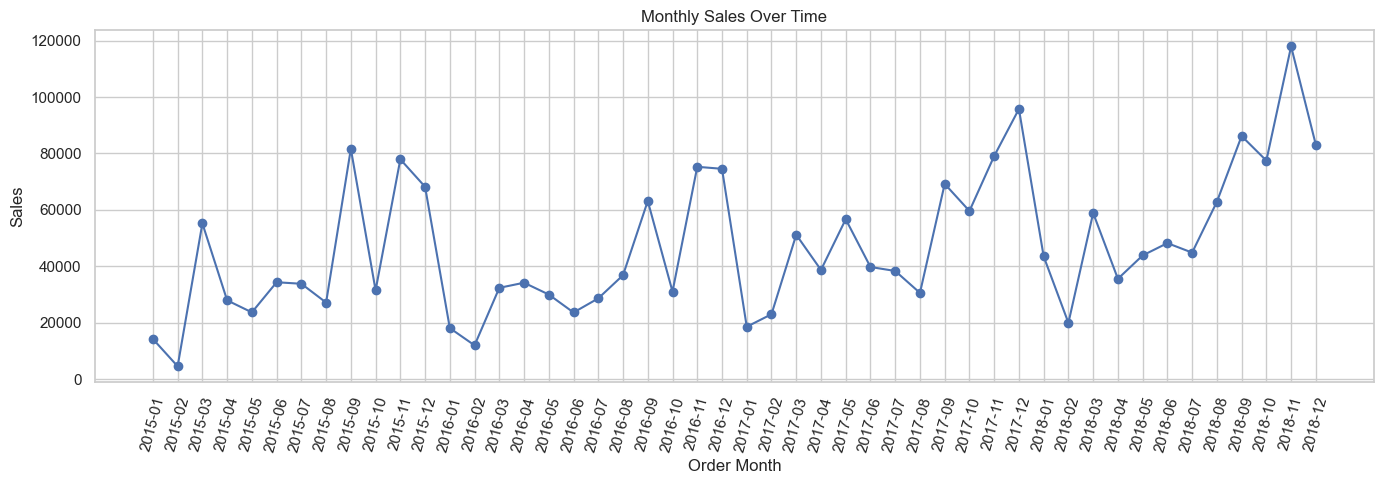

In [19]:
monthly_sales_plot = monthly_sales.copy()
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales_plot.index.astype(str), monthly_sales_plot.values, marker="o")
plt.title("Monthly Sales Over Time")
plt.xlabel("Order Month")
plt.ylabel("Sales")
plt.xticks(rotation=75)
plt.tight_layout()
plt.savefig("../charts/monthly sales.png")
plt.show()

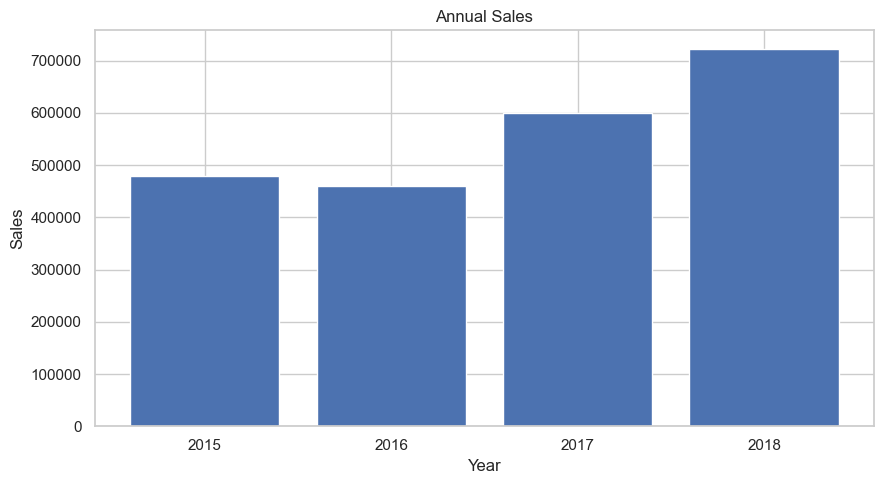

In [20]:
plt.figure(figsize=(9, 5))
plt.bar(yearly_sales.index.astype(str), yearly_sales.values)
plt.title("Annual Sales")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../charts/Annual Sales.png")
plt.show()

## 7. Product and Category Analysis

Compare categories and sub-categories by sales. These figures represent sales value, not product quantity.

In [21]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)
top_products = df.groupby("Product Name")["Sales"].sum().nlargest(10)

display(category_sales.rename("Sales").to_frame())
display(subcategory_sales.rename("Sales").to_frame())
display(top_products.rename("Sales").to_frame())

,Sales
Category,
Technology,"827,455.87"
Furniture,"728,658.58"
Office Supplies,"705,422.33"


,Sales
Sub-Category,
Phones,"327,782.45"
Chairs,"322,822.73"
Storage,"219,343.39"
Tables,"202,810.63"
Binders,"200,028.79"
Machines,"189,238.63"
Accessories,"164,186.70"
Copiers,"146,248.09"
Bookcases,"113,813.20"


,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,"61,599.82"
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,"27,453.38"
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48"
HON 5400 Series Task Chairs for Big and Tall,"21,870.58"
GBC DocuBind TL300 Electric Binding System,"19,823.48"
GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50"
Hewlett Packard LaserJet 3310 Copier,"18,839.69"
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color","18,374.90"
GBC DocuBind P400 Electric Binding System,"17,965.07"


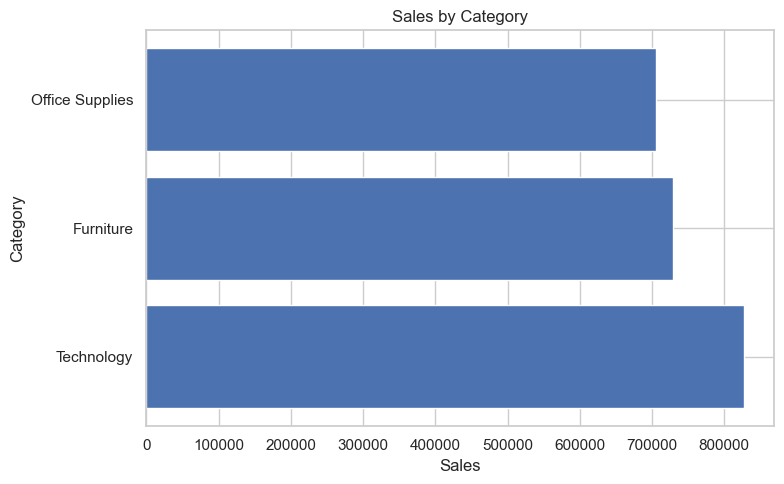

In [22]:
plt.figure(figsize=(8, 5))
plt.barh(category_sales.index, category_sales.values)
plt.title("Sales by Category")
plt.xlabel("Sales")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("../charts/Sales by Category.png")
plt.show()

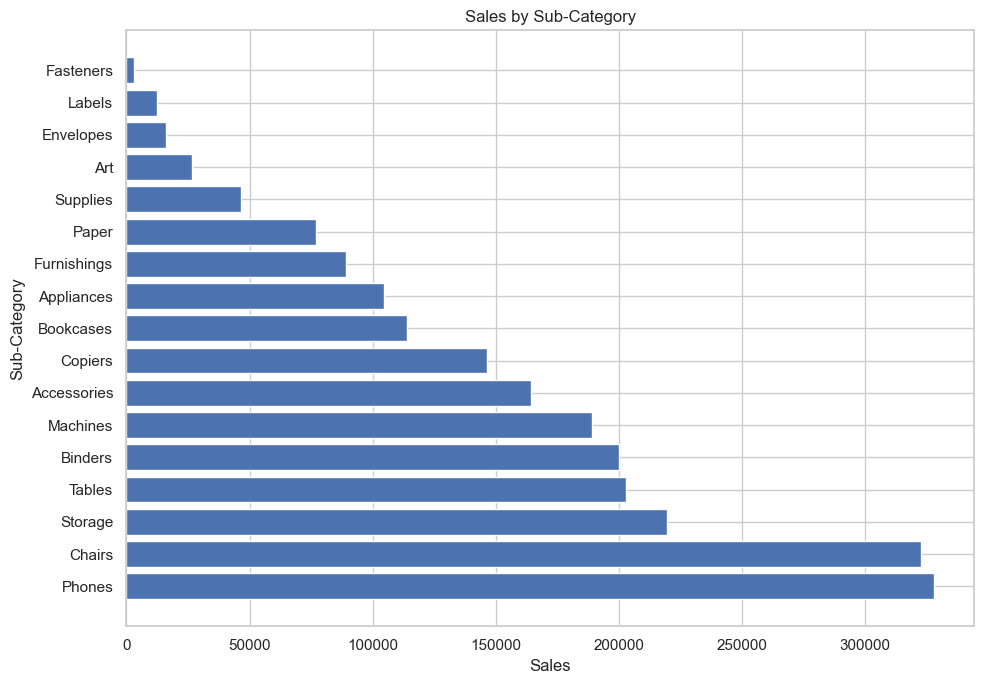

In [23]:
plt.figure(figsize=(10, 7))
plt.barh(subcategory_sales.index, subcategory_sales.values)
plt.title("Sales by Sub-Category")
plt.xlabel("Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig("../charts/Sales by Sub-Category.png")
plt.show()

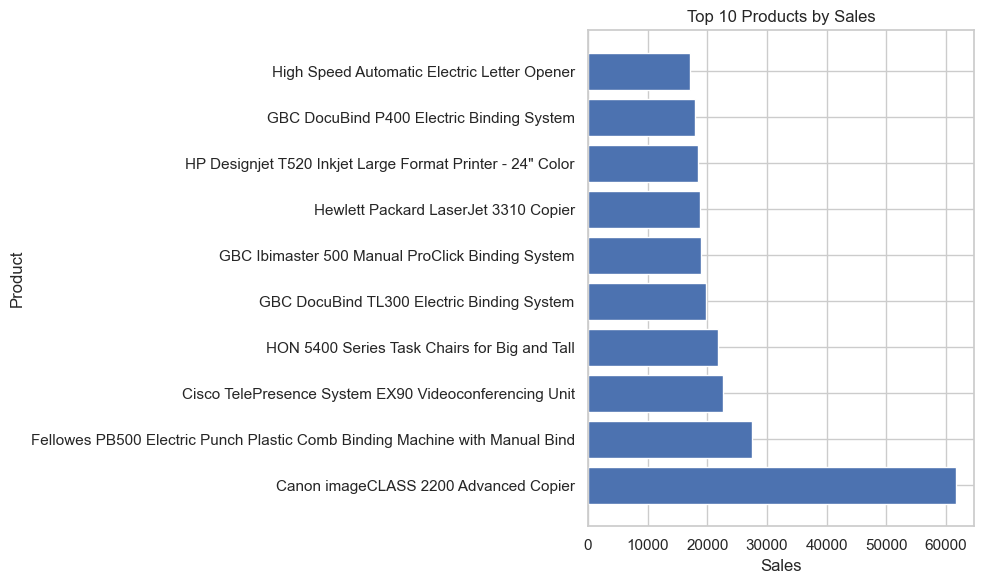

In [24]:
plt.figure(figsize=(10, 6))
plt.barh(top_products.index, top_products.values)
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("../charts/Top 10 Products by Sales.png")
plt.show()

## 8. Customer Analysis

Rank customers by total sales. The result identifies customers with the highest recorded sales value; it does not establish customer lifetime value or profitability.

In [25]:
customer_sales = (
    df.groupby(["Customer ID", "Customer Name"])["Sales"]
      .sum()
      .sort_values(ascending=False)
)
top_customers = customer_sales.head(10)
display(top_customers.to_frame("Total Sales"))

,,Total Sales
Customer ID,Customer Name,
SM-20320,Sean Miller,"25,043.05"
TC-20980,Tamara Chand,"19,052.22"
RB-19360,Raymond Buch,"15,117.34"
TA-21385,Tom Ashbrook,"14,595.62"
AB-10105,Adrian Barton,"14,473.57"
KL-16645,Ken Lonsdale,"14,175.23"
SC-20095,Sanjit Chand,"14,142.33"
HL-15040,Hunter Lopez,"12,873.30"
SE-20110,Sanjit Engle,"12,209.44"


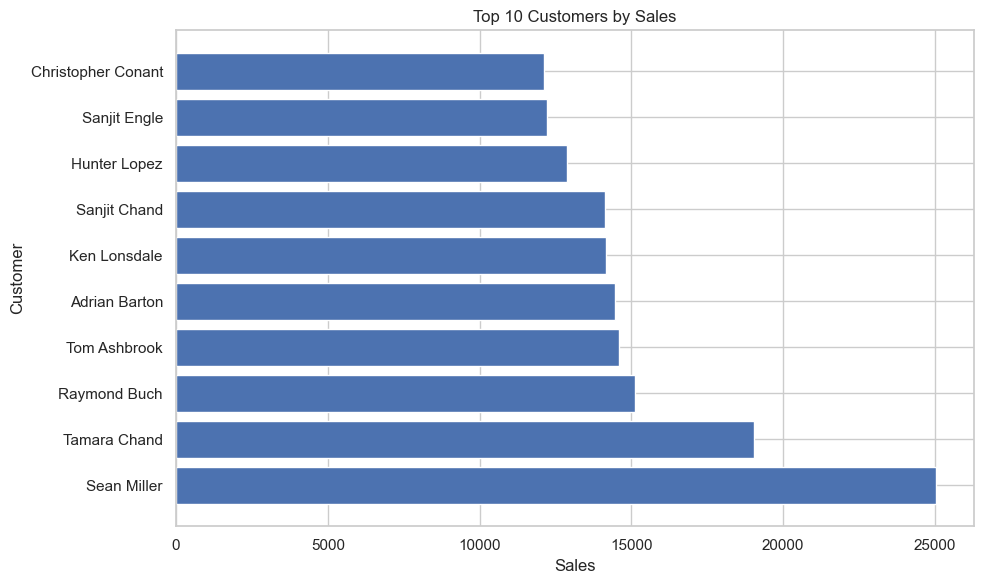

In [26]:
plt.figure(figsize=(10, 6))
plt.barh([name for _, name in top_customers.index], top_customers.values)
plt.title("Top 10 Customers by Sales")
plt.xlabel("Sales")
plt.ylabel("Customer")
plt.tight_layout()
plt.savefig("../charts/Top 10 Customers by Sales.png")
plt.show()

## 9. Regional and Shipping Analysis

Compare sales by region and state. Also review shipping duration by shipping mode.

In [27]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10)
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False).head(10)

display(region_sales.rename("Sales").to_frame())
display(state_sales.rename("Sales").to_frame())
display(city_sales.rename("Sales").to_frame())

,Sales
Region,
West,"710,219.68"
East,"669,518.73"
Central,"492,646.91"
South,"389,151.46"


,Sales
State,
California,"446,306.46"
New York,"306,361.15"
Texas,"168,572.53"
Washington,"135,206.85"
Pennsylvania,"116,276.65"
Florida,"88,436.53"
Illinois,"79,236.52"
Michigan,"76,136.07"
Ohio,"75,130.35"


,Sales
City,
New York City,"252,462.55"
Los Angeles,"173,420.18"
Seattle,"116,106.32"
San Francisco,"109,041.12"
Philadelphia,"108,841.75"
Houston,"63,956.14"
Chicago,"47,820.13"
San Diego,"47,521.03"
Jacksonville,"44,713.18"


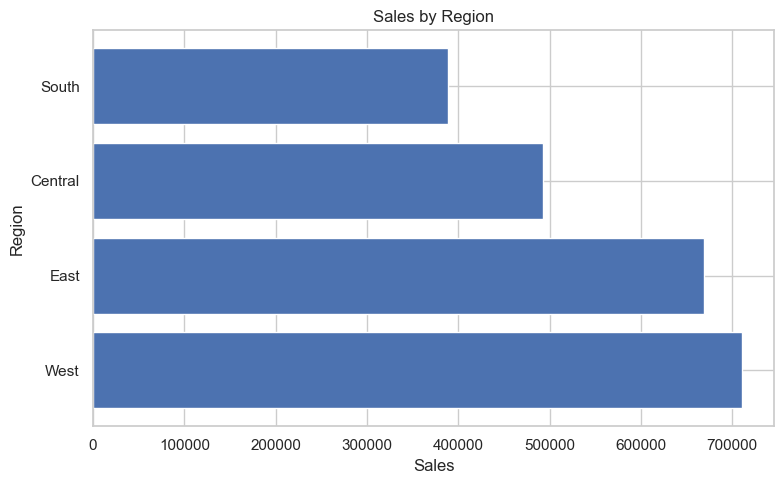

In [28]:
plt.figure(figsize=(8, 5))
plt.barh(region_sales.index, region_sales.values)
plt.title("Sales by Region")
plt.xlabel("Sales")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("../charts/Sales by Region.png")
plt.show()

In [29]:
shipping_summary = (
    df.groupby("Ship Mode")["Shipping Days"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean")
)
display(shipping_summary)

,count,mean,median,min,max
Ship Mode,,,,,
Same Day,538,0.04,0.00,0,1
First Class,1501,2.18,2.00,1,4
Second Class,1902,3.25,3.00,1,5
Standard Class,5859,5.01,5.00,3,7


## 10. Statistical Analysis

### Descriptive statistics and sales distribution

Sales values can be strongly right-skewed because a small number of transactions may be much larger than typical transactions. Compare the mean and median and inspect the distribution.

In [30]:
display(df["Sales"].describe().to_frame("Sales"))
print(f"Skewness: {df['Sales'].skew():.3f}")
print(f"Kurtosis: {df['Sales'].kurtosis():.3f}")

,Sales
count,"9,800.00"
mean,230.77
std,626.65
min,0.44
25%,17.25
50%,54.49
75%,210.61
max,"22,638.48"


Skewness: 12.983
Kurtosis: 304.445


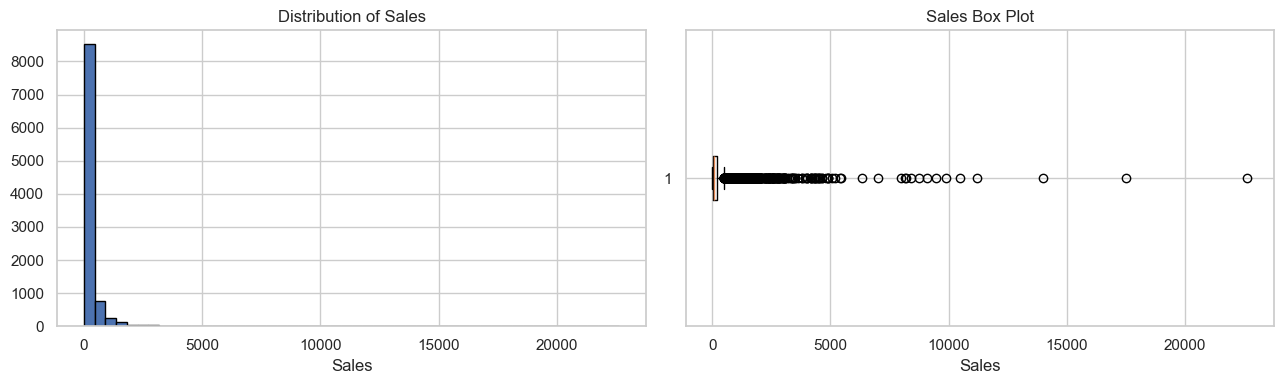

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["Sales"], bins=50, edgecolor="black")
axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales")

axes[1].boxplot(df["Sales"], vert=False)
axes[1].set_title("Sales Box Plot")
axes[1].set_xlabel("Sales")

plt.tight_layout()
plt.savefig("../charts/Distribution of Sales.png")
plt.savefig("../charts/Sales Box Plot.png")
plt.show()

### IQR-based outlier inspection

The Interquartile Range (IQR) rule flags unusually high or low sales values for investigation. These observations are **not automatically removed**, because high-value transactions may be genuine.

In [32]:
q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (df["Sales"] < lower_bound) | (df["Sales"] > upper_bound)
outlier_count = int(outlier_mask.sum())

print(f"Lower IQR boundary: {lower_bound:,.2f}")
print(f"Upper IQR boundary: {upper_bound:,.2f}")
print(f"Flagged sales rows: {outlier_count:,} ({outlier_count / len(df) * 100:.2f}%)")

display(df.loc[outlier_mask, ["Order ID", "Product Name", "Category", "Sales"]]
          .sort_values("Sales", ascending=False).head(10))

Lower IQR boundary: -272.79
Upper IQR boundary: 500.64
Flagged sales rows: 1,145 (11.68%)


,Order ID,Product Name,Category,Sales
2697,CA-2015-145317,Cisco TelePresence System EX90 Videoconferenci...,Technology,"22,638.48"
6826,CA-2017-118689,Canon imageCLASS 2200 Advanced Copier,Technology,"17,499.95"
8153,CA-2018-140151,Canon imageCLASS 2200 Advanced Copier,Technology,"13,999.96"
2623,CA-2018-127180,Canon imageCLASS 2200 Advanced Copier,Technology,"11,199.97"
4190,CA-2018-166709,Canon imageCLASS 2200 Advanced Copier,Technology,"10,499.97"
9039,CA-2017-117121,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,"9,892.74"
4098,CA-2015-116904,Ibico EPK-21 Electric Binding System,Office Supplies,"9,449.95"
4277,US-2017-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,"9,099.93"
8488,CA-2017-158841,HP Designjet T520 Inkjet Large Format Printer ...,Technology,"8,749.95"
6425,CA-2017-143714,Canon imageCLASS 2200 Advanced Copier,Technology,"8,399.98"


### Category-level statistical comparison

A Kruskal–Wallis test compares the distributions of sales values across the three product categories. It is a non-parametric test. A small p-value indicates evidence that at least one category's sales distribution differs; it does not identify which pair differs.

In [33]:
from scipy.stats import kruskal

category_samples = [
    group["Sales"].to_numpy()
    for _, group in df.groupby("Category")
]

if len(category_samples) >= 2 and all(len(sample) > 0 for sample in category_samples):
    statistic, p_value = kruskal(*category_samples)
    print(f"Kruskal-Wallis statistic: {statistic:.4f}")
    print(f"p-value: {p_value:.6g}")
    if p_value < 0.05:
        print("At the 5% significance level, the sales distributions are not all the same.")
    else:
        print("At the 5% significance level, there is insufficient evidence of a difference.")
else:
    print("Not enough category groups to perform the test.")

Kruskal-Wallis statistic: 2208.5629
p-value: 0
At the 5% significance level, the sales distributions are not all the same.


## 11. Correlation Analysis

Only numeric columns are included. `Row ID` and `Postal Code` are identifiers/location codes, so interpret their correlations cautiously. Correlation does not establish causation.

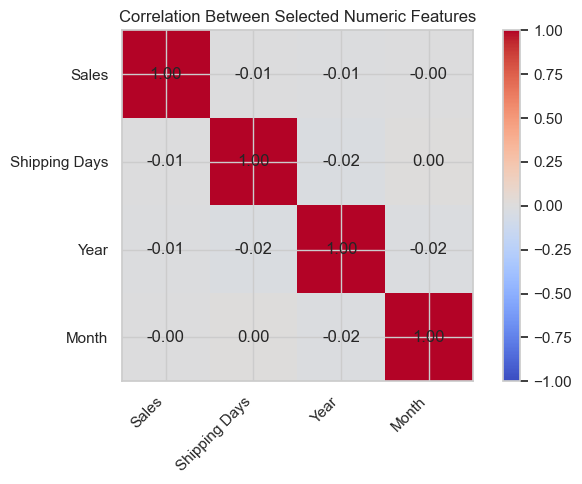

,Sales,Shipping Days,Year,Month
Sales,1.00,-0.01,-0.01,-0.00
Shipping Days,-0.01,1.00,-0.02,0.00
Year,-0.01,-0.02,1.00,-0.02
Month,-0.00,0.00,-0.02,1.00


In [34]:
numeric_corr = df[["Sales", "Shipping Days", "Year", "Month"]].corr()

plt.figure(figsize=(7, 5))
image = plt.imshow(numeric_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(image, ax=plt.gca())
plt.xticks(range(len(numeric_corr.columns)), numeric_corr.columns, rotation=45, ha="right")
plt.yticks(range(len(numeric_corr.index)), numeric_corr.index)
for row in range(len(numeric_corr.index)):
    for column in range(len(numeric_corr.columns)):
        plt.text(column, row, f"{numeric_corr.iloc[row, column]:.2f}",
                 ha="center", va="center")
plt.title("Correlation Between Selected Numeric Features")
plt.tight_layout()
plt.savefig("../charts/Heatmap.png")
plt.show()

display(numeric_corr)

## 12. Key Business Insights

The following cells calculate the main findings from the cleaned dataset. Use the actual outputs when presenting the project; avoid interpreting sales as profit.

In [35]:
best_year = yearly_sales.idxmax()
best_category = category_sales.idxmax()
best_subcategory = subcategory_sales.idxmax()
best_region = region_sales.idxmax()
best_month = monthly_sales.idxmax()

print(f"Total sales: ${total_sales:,.2f}")
print(f"Highest-sales year: {best_year} (${yearly_sales.loc[best_year]:,.2f})")
print(f"Highest-sales category: {best_category} (${category_sales.loc[best_category]:,.2f})")
print(f"Highest-sales sub-category: {best_subcategory} (${subcategory_sales.loc[best_subcategory]:,.2f})")
print(f"Highest-sales region: {best_region} (${region_sales.loc[best_region]:,.2f})")
print(f"Highest-sales month: {best_month} (${monthly_sales.loc[best_month]:,.2f})")
print(f"Average shipping duration: {df['Shipping Days'].mean():.2f} days")

Total sales: $2,261,536.78
Highest-sales year: 2018 ($722,052.02)
Highest-sales category: Technology ($827,455.87)
Highest-sales sub-category: Phones ($327,782.45)
Highest-sales region: West ($710,219.68)
Highest-sales month: 2018-11 ($117,938.15)
Average shipping duration: 3.96 days


### Interpretation prompts
After running the notebook, write 3–5 concise observations based on the outputs:
- Which year had the highest sales, and how did sales change year over year?
- Which category and sub-category generated the most sales?
- Which region had the highest sales?
- How different are the mean and median sales values? What does this suggest about skewness?
- What does the shipping-duration summary show across shipping modes?

## 13. Conclusion

This project uses Python to clean, explore, analyze, and visualize retail sales data. It examines sales trends over time, product and category performance, customer contributions, regional patterns, shipping duration, and the distribution of sales values. The findings can support further business investigation and data-driven planning.

## 14. Limitations and Future Work

- The dataset does not include profit, cost, quantity, or discount, so profitability and unit-volume analysis are outside this project's scope.
- The IQR rule flags potential outliers but does not determine whether they are errors.
- The category comparison is an overall statistical test; pairwise follow-up tests would be needed to locate specific differences.
- Future work could add forecasting, customer segmentation, and analysis using a dataset with profit and quantity fields.